In [146]:
import pandas as pd
import matplotlib.pyplot as plt
from plotnine import *
import numpy as np

In [147]:
# Import both datasets

# SEQ = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha_detectionsgeodata.tsv"
SEQ = "./metadata/sequence_metadata/NCBI-BVBRC_ha_detectionsgeodata.tsv"
ha_seq = pd.read_csv(SEQ, sep = "\t")
ha_seq["year_month"] = ha_seq["ncbibvbrc_date"].str.split("-", expand = True)[0] + "/" + ha_seq["ncbibvbrc_date"].str.split("-", expand = True)[1]

ALL_DETECT = "./metadata/detections_data/combinedNAm_detections_2021-2025.csv"
concat_detections = pd.read_csv(ALL_DETECT, sep = ",")
concat_detections["year_month"] = concat_detections["Collection Date"].str.split("-", expand = True)[0] + "/" + concat_detections["Collection Date"].str.split("-", expand = True)[1]

In [148]:
print(f"Number of sequences from North American wild birds: {len(ha_seq)}")
print(f"Number of North American detections: {len(concat_detections)}")

Number of sequences from North American wild birds: 5869
Number of North American detections: 19348


In [149]:
# Count the size of each per year_month

ha_seq_counts = pd.DataFrame(ha_seq.groupby("year_month").size().sort_index()).rename({0:"count"}, axis = 1)
detect_counts = pd.DataFrame(concat_detections.groupby("year_month").size().sort_index()).rename({0:"count"}, axis = 1)

ha_seq_counts["type"] = "HA Sequences"
detect_counts["type"] = "Detections"

ha_seq_counts = ha_seq_counts.reset_index()
detect_counts = detect_counts.reset_index()

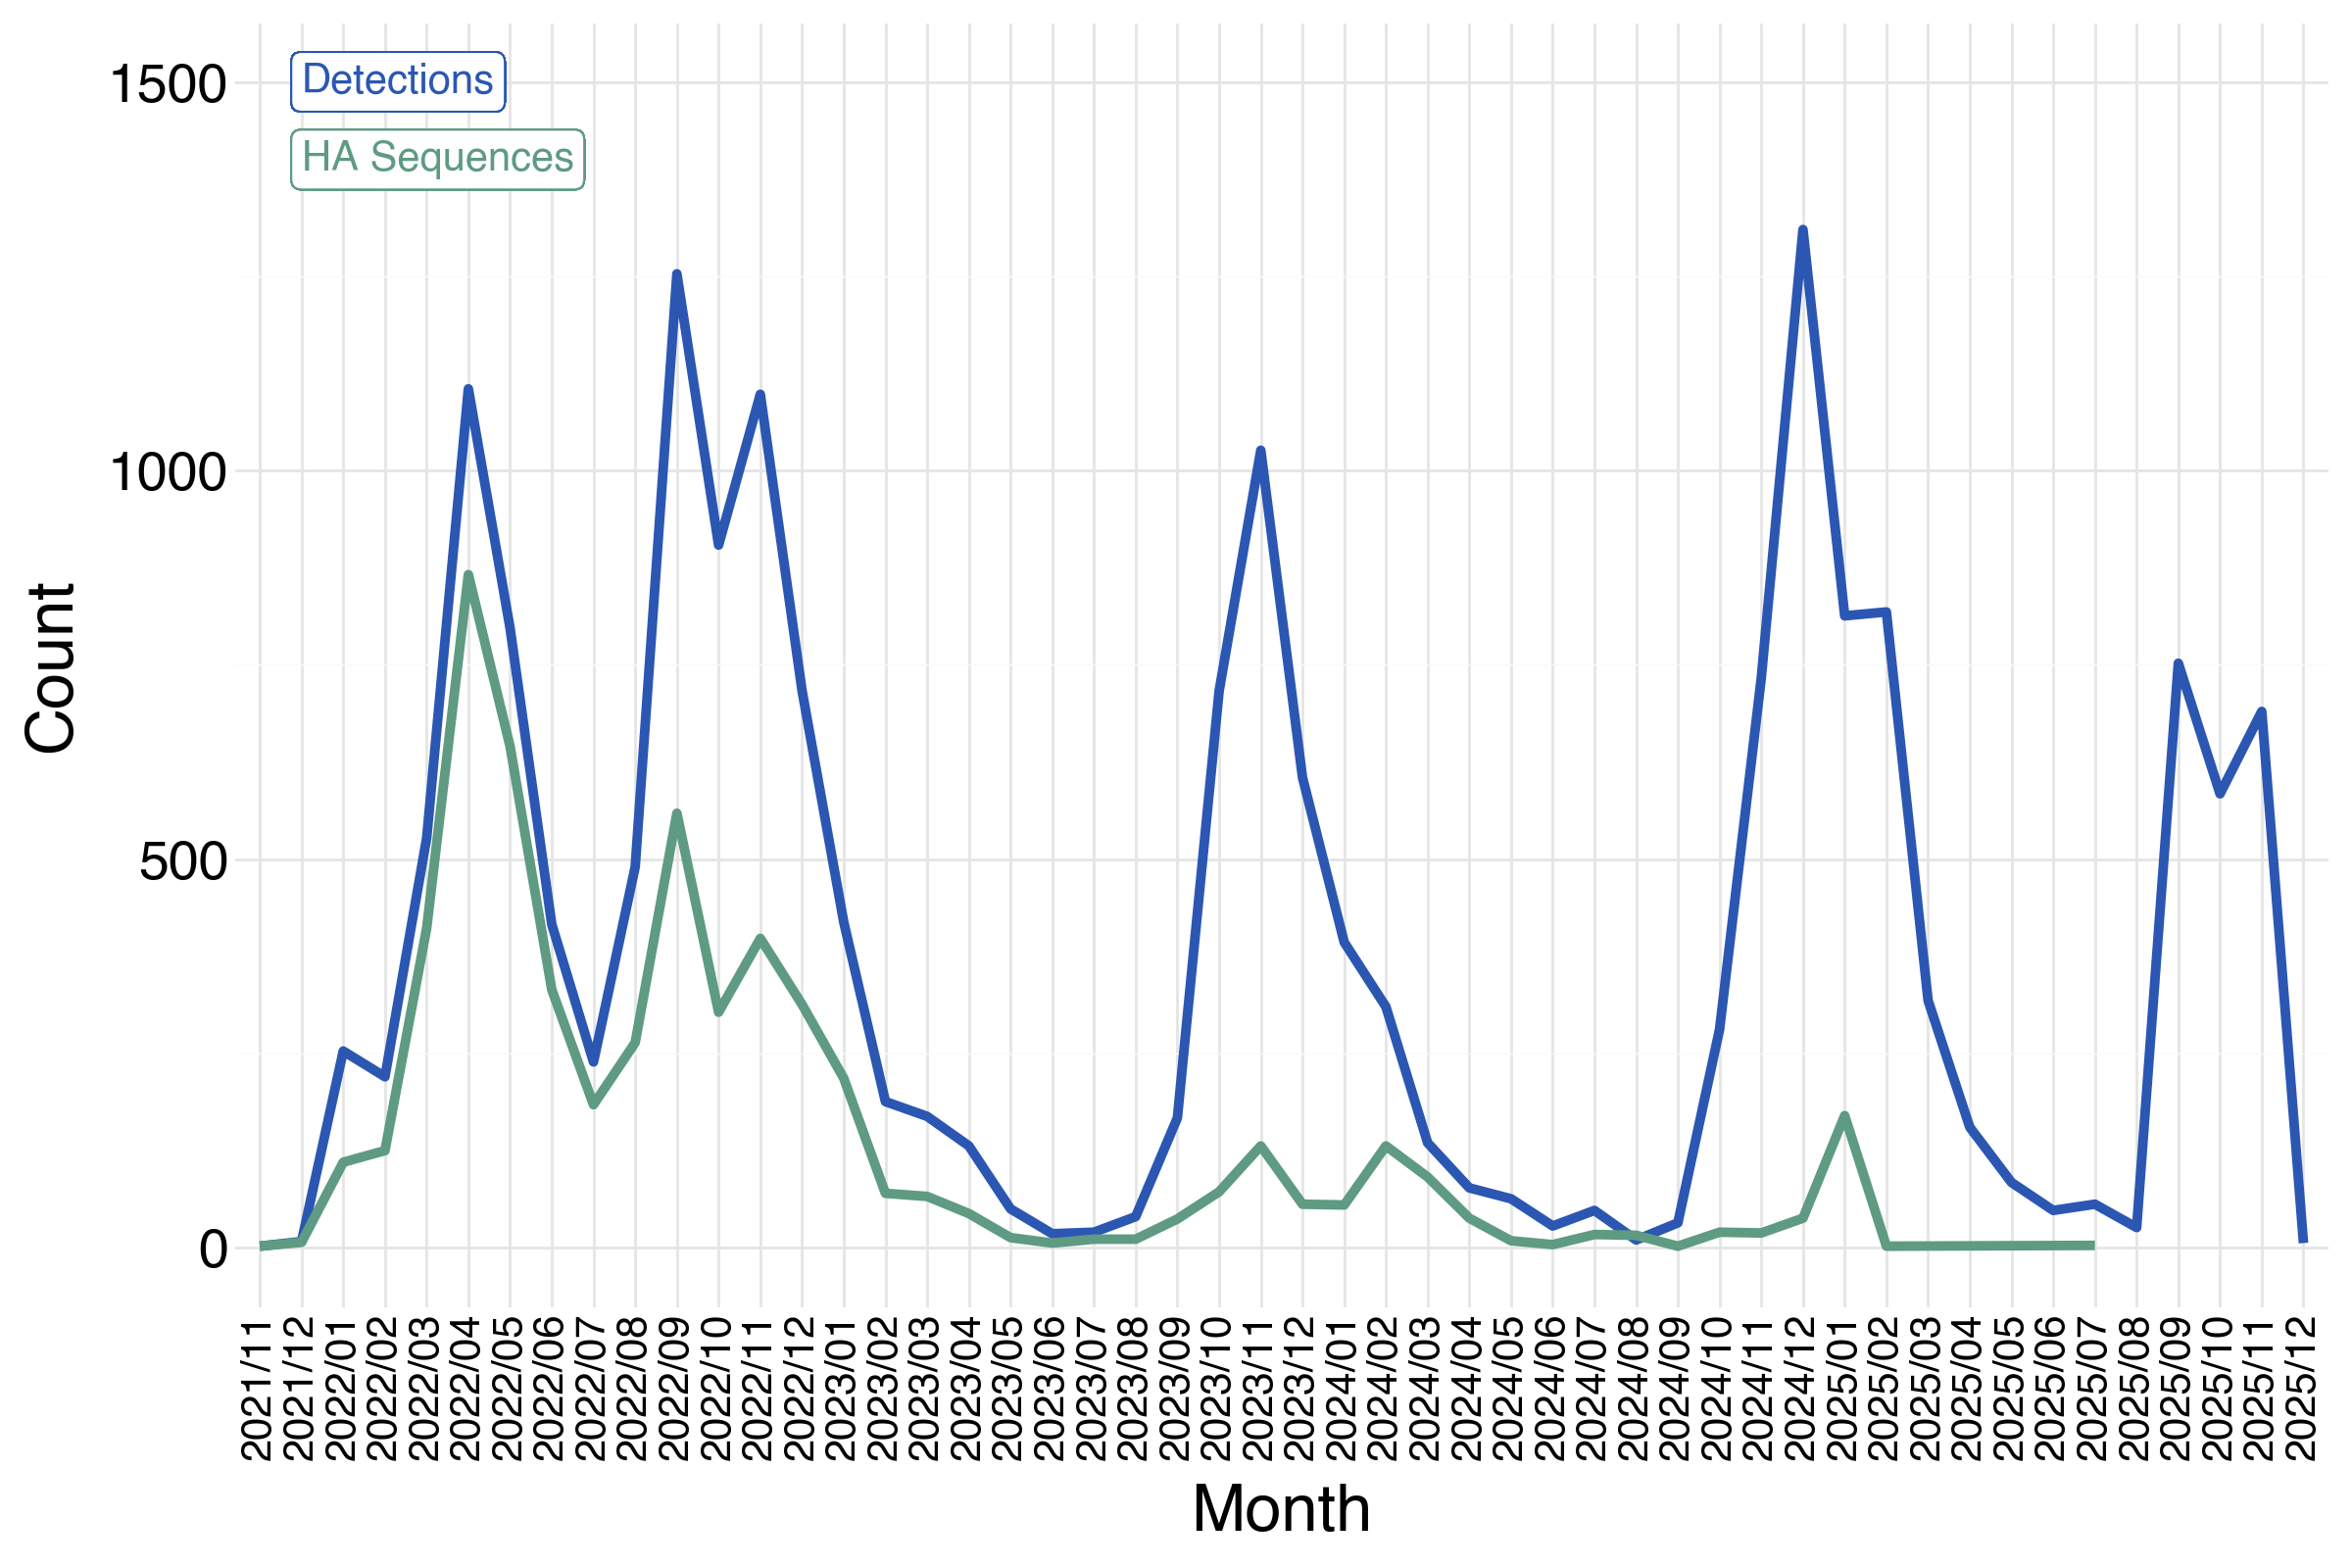

In [150]:
plt_ALL = (
    ggplot()
    + geom_line(data = detect_counts, mapping = aes(x = "year_month", y = "count", group = 1), color = "#2B57B3", size = 2)
    + geom_line(data = ha_seq_counts, mapping= aes(x = "year_month", y = "count", group = 1), color = "#5E9B82", size = 2)
    + geom_label(data = detect_counts, mapping = aes(x = 2, y = 1500, label = "type"), color = "#2B57B3", size = 15, ha = "left")
    + geom_label(data = ha_seq_counts, mapping = aes(x = 2, y = 1400, label = "type"), color = "#5E9B82", size = 15, ha = "left")
    + labs(x = "Month", y = "Count")
    + ylim(-1, 1500)                                                
    + theme_minimal()
    + theme(figure_size = (12,8), 
            axis_title_x = element_text(size = 24), axis_text_y=element_text(size=20, color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 15, rotation = 90, color = "black"))
)

plt_ALL.show()

In [151]:
def filling_in_dates(df, months, GROUP = True):

    df_new = df.reset_index() # Set the index to a combo of month and host

    new_rows = []

    if GROUP == True: # If you have multiple types
        for group, grouped in df_new.groupby("hostType"):
            for i in months: 
                if i in set(grouped["year_month"]): # if there is already an entry for this month
                    pass # do nothing
                else: # if the month has no cases or sequences
                    # print(i)
                    new_rows.append({"year_month":i, "hostType":group, "count":0}) # add a count of 0
    else:
        for i in months: 
            if i in set(grouped["year_month"]):
                pass
            else:
                # print(i)
                new_rows.append({"year_month":i, "hostType":group, "count":0})

    # print(new_rows)
    new_rows_df = pd.DataFrame(new_rows)
    df_final = pd.concat([df_new, new_rows_df])

    return(df_final)

In [152]:
months = ['2021/11', '2021/12', 
          '2022/01', '2022/02', '2022/03', '2022/04', '2022/05', '2022/06', '2022/07', '2022/08', '2022/09', '2022/10', '2022/11', '2022/12', 
          '2023/01', '2023/02', '2023/03', '2023/04', '2023/05', '2023/06', '2023/07', '2023/08', '2023/09', '2023/10', '2023/11', '2023/12',
          '2024/01', '2024/02', '2024/03', '2024/04', '2024/05', '2024/06', '2024/07', '2024/08', '2024/09', '2024/10', '2024/11', '2024/12', 
          '2025/01', '2025/02', '2025/03', '2025/04', '2025/05', '2025/06', '2025/07', '2025/08', '2025/09', '2025/10', '2025/11', '2025/12'
          ]

In [153]:
# Count just the ducks and geese

duck_ha_seq_counts = pd.DataFrame(ha_seq[ha_seq["ncbibvbrc_hostgroup"] == "duck"].groupby("year_month").size().sort_index()).rename({0:"count"}, axis = 1)
goose_ha_seq_counts = pd.DataFrame(ha_seq[ha_seq["ncbibvbrc_hostgroup"] == "goose-swan"].groupby("year_month").size().sort_index()).rename({0:"count"}, axis = 1)

duck_detect_counts = pd.DataFrame(concat_detections[concat_detections["Host_Broad"] == "duck"].groupby("year_month").size().sort_index()).rename({0:"count"}, axis = 1)
goose_detect_counts = pd.DataFrame(concat_detections[concat_detections["Host_Broad"] == "goose-swan"].groupby("year_month").size().sort_index()).rename({0:"count"}, axis = 1)

duck_ha_seq_counts["hostType"] = "duck"
goose_ha_seq_counts["hostType"] = "goose-swan"
duck_detect_counts["hostType"] = "duck"
goose_detect_counts["hostType"] = "goose-swan"

dg_ha_seq_counts = pd.concat([duck_ha_seq_counts, goose_ha_seq_counts], join = "outer")
dg_detect_counts = pd.concat([duck_detect_counts, goose_detect_counts], join = "outer")

dg_ha_seq_counts_upt = filling_in_dates(dg_ha_seq_counts, months, GROUP = True)
dg_detect_counts_upt = filling_in_dates(dg_detect_counts, months, GROUP = True)

dg_ha_seq_counts_upt["type"] = "HA Sequences"
dg_detect_counts_upt["type"] = "Detections"

In [160]:
dg_all_counts = pd.concat([dg_ha_seq_counts_upt, dg_detect_counts_upt], join = "outer")
dg_all_counts["group"] = dg_all_counts["hostType"] + "_" + dg_all_counts["type"]
print(dg_all_counts)

   year_month  count    hostType          type                  group
0     2021/12      5        duck  HA Sequences      duck_HA Sequences
1     2022/01    101        duck  HA Sequences      duck_HA Sequences
2     2022/02     45        duck  HA Sequences      duck_HA Sequences
3     2022/03     43        duck  HA Sequences      duck_HA Sequences
4     2022/04     50        duck  HA Sequences      duck_HA Sequences
..        ...    ...         ...           ...                    ...
10    2023/07      0  goose-swan    Detections  goose-swan_Detections
11    2023/08      0  goose-swan    Detections  goose-swan_Detections
12    2024/07      0  goose-swan    Detections  goose-swan_Detections
13    2024/08      0  goose-swan    Detections  goose-swan_Detections
14    2024/09      0  goose-swan    Detections  goose-swan_Detections

[200 rows x 5 columns]


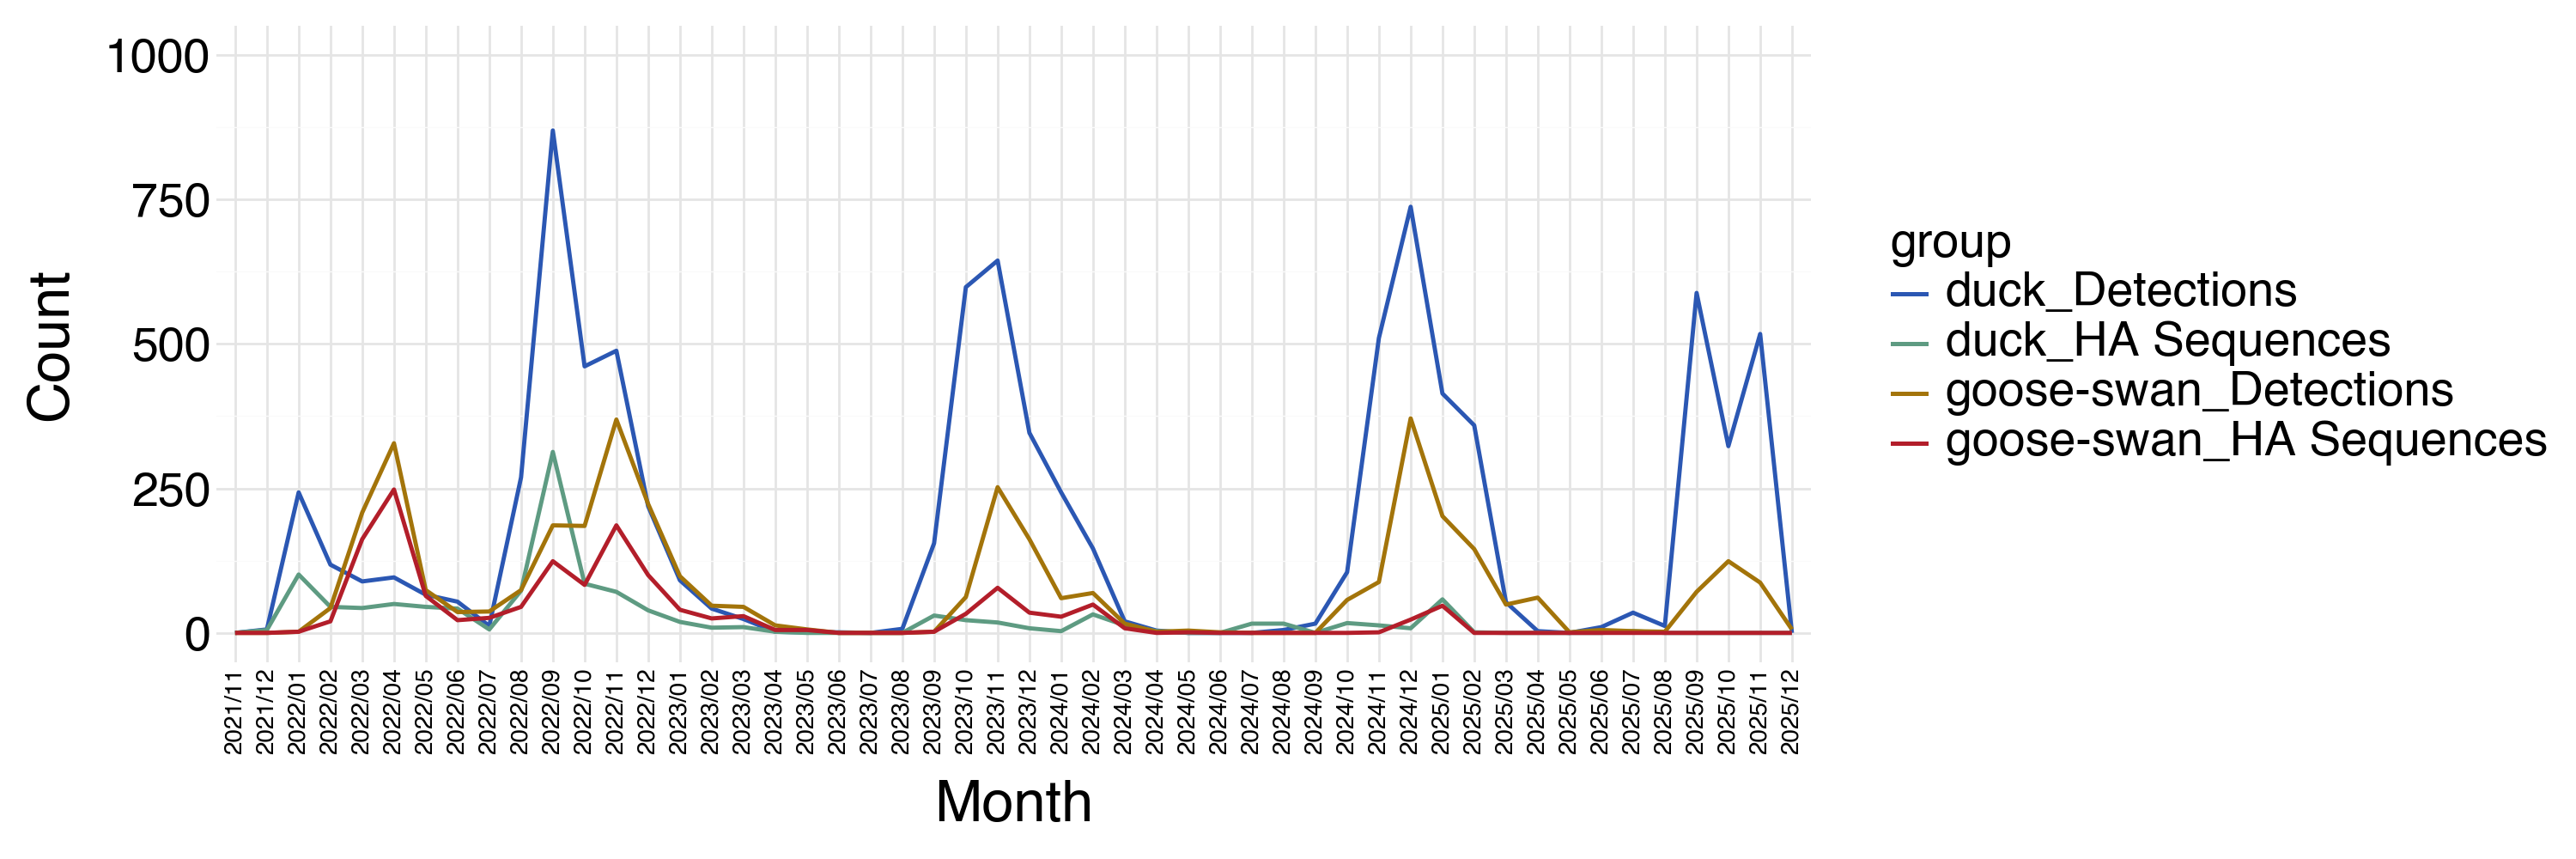

In [166]:
plt_DG = (
    ggplot()
    # + geom_line(data = dg_detect_counts_upt, mapping = aes(x = "year_month", y = "count", group = 1), color = "#2B57B3", size = 1)
    # + geom_line(data = dg_ha_seq_counts_upt, mapping= aes(x = "year_month", y = "count", group = 1), color = "#5E9B82", size = 1)
    # + geom_label(data = dg_detect_counts, mapping = aes(x = 2, y = 1500, label = "type"), color = "#2B57B3", size = 10, ha = "left")
    # + geom_label(data = dg_ha_seq_counts, mapping = aes(x = 2, y = 1400, label = "type"), color = "#5E9B82", size = 10, ha = "left")
    + geom_line(data = dg_all_counts, mapping = aes(x = "year_month", y = "count", group = "group", color = "group"), size = 1)
    # + facet_wrap("hostType", labeller = {"duck":"Duck", "goose-swan":"Geese and Swans"})
    + scale_color_manual(values = {"duck_HA Sequences":"#5E9B82", "goose-swan_HA Sequences":"#B31E2A", "duck_Detections":"#2B57B3", "goose-swan_Detections":"#A3740A"})
    + labs(x = "Month", y = "Count")
    + ylim(-1, 1000)                                                
    + theme_minimal()
    + theme(figure_size = (15,5), text = element_text(size = 20),
            axis_title_x = element_text(size = 24), axis_text_y=element_text(size=20, color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 10, rotation = 90, color = "black"))
)

plt_DG.show()